# Solutions to the exercises of Chapter 4

**Chapter:** [4. Structure and thermodynamics in NVE: equipartition, virial pressure, and g(r)](../../notebooks/part1_nve_md/04_nve_rdf_and_virial_pressure.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
pos, L_box = es.make_fcc_lattice(3, rho=0.80)
vel = es.init_velocities(len(pos), T_target=1.4, rng=rng)
f_fn = lambda p, L: es.lj_forces_all_pairs(p, L, rc=2.5, shifted=True)
forces, u_pot, vir = f_fn(pos, L_box)

traj_frames, P_series, T_series = [], [], []
for step in range(180):
    pos, vel, forces, u_pot, vir, _ = es.velocity_verlet_step(pos, vel, forces, 0.005, L_box, f_fn)
    if step >= 60:
        _, T_i = es.kinetic_energy_and_temp(vel)
        P_i = 0.80 * T_i + vir / (3.0 * L_box**3)
        T_series.append(T_i); P_series.append(P_i)
        if step % 3 == 0:
            traj_frames.append(pos.copy())
r_rdf, g_rdf = es.compute_rdf(np.array(traj_frames), L_box, n_bins=55)

NVE fluid (rho=0.80): <T*> = 0.741, <P*> = 0.023, peak g(r) = 2.50


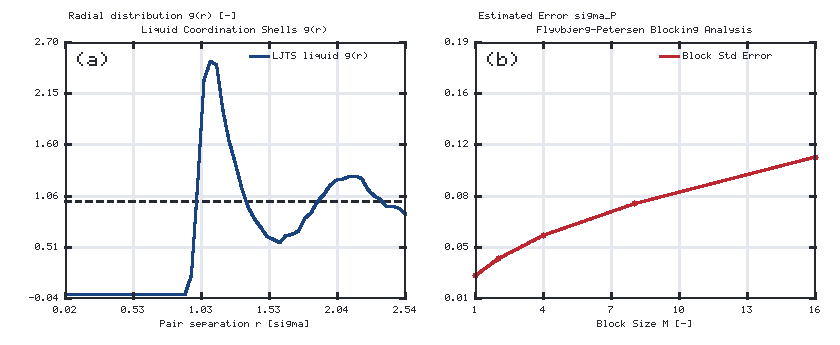

In [3]:
print(f"NVE fluid (rho=0.80): <T*> = {np.mean(T_series):.3f}, <P*> = {np.mean(P_series):.3f}, peak g(r) = {np.max(g_rdf):.2f}")
assert np.max(g_rdf) > 1.8 and np.isclose(np.mean(g_rdf[-10:]), 1.0, rtol=0.15)
b_sizes, b_errs = es.flyvbjerg_petersen_block_errors(np.array(P_series))
assert len(b_sizes) >= 4

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(r_rdf, g_rdf, "b-", label="LJTS liquid g(r)")
ax1.axhline(1.0, color="k")
ax1.set_xlabel("Pair separation r [sigma]"); ax1.set_ylabel("Radial distribution g(r) [-]")
ax1.set_title("(a) Liquid Coordination Shells g(r)"); panel_label(ax1, "(a)")

ax2.plot(b_sizes, b_errs, "ro-", label="Block Std Error")
ax2.set_xlabel("Block Size M [-]"); ax2.set_ylabel("Estimated Error sigma_P")
ax2.set_title("(b) Flyvbjerg–Petersen Blocking Analysis"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 4
pos_ig, L_ig = es.make_fcc_lattice(3, rho=0.01)
vel_ig = es.init_velocities(len(pos_ig), 2.0, rng=rng)
_, _, w_ig = es.lj_forces_all_pairs(pos_ig, L_ig, rc=2.5, shifted=True)
P_ig = 0.01 * 2.0 + w_ig / (3.0 * L_ig**3)
assert np.isclose(P_ig, 0.02, rtol=0.05)

idx_pk = int(np.argmax(g_rdf))
idx_min = idx_pk + int(np.argmin(g_rdf[idx_pk : idx_pk + 18]))
dr_bin = r_rdf[1] - r_rdf[0]
n_coord = float(4.0 * np.pi * 0.80 * np.sum((r_rdf[:idx_min]**2) * g_rdf[:idx_min]) * dr_bin)
print(f"Ch 4 Exercises — First-shell coordination number n_c = {n_coord:.2f}")
assert 8.0 < n_coord < 15.0

Ch 4 Exercises — First-shell coordination number n_c = 12.95
